In [1]:
import wrds
db = wrds.Connection(wrds_username='jiarenyu')
db.create_pgpass_file()

/Users/yujr0612/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Loading library list...
Done


In [11]:
sp_500 = db.raw_sql('''
SELECT permno, start, ending 
FROM crsp.msp500list 
''')

In [129]:
mag7_permno = [14593,  # AAPL 
               10107,  # MSFT
               86580,  # NVDA
               84788,  # AMZN
               13407,  # META
               90319,  # GOOGL
               93436]  # TSLA

In [ ]:
import wrds
import pandas as pd

conn = wrds.Connection()

permno_list = [14593, 10107, 86580, 84788, 13407, 90319, 93436]
#WHERE permno IN ({', '.join(map(str, permno_list))})

query = f"""
    SELECT dlycaldt,dlycap,dlyprc,dlyret,dlyretx,dlyvol,permno,shrout,siccd,ticker
    FROM crsp.dsf_v2
      WHERE dlycaldt BETWEEN '2010-01-01' AND '2024-12-31'
    ORDER BY dlycaldt, permno
"""

df = conn.raw_sql(query)

df['date'] = pd.to_datetime(df['dlycaldt'])

df['cap'] = df['dlyprc'].abs() * df['shrout']

print(df.head())

WRDS recommends setting up a .pgpass file.
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


In [20]:
df.to_csv('dsf_v2_all.csv',index=True)

In [130]:
import yfinance as yf
import pandas as pd
from datetime import datetime
dsf_v2 = pd.read_csv('dsf_v2.csv')

mag7_tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]
permno_map = {
    "AAPL": 14593,
    "MSFT": 10107,
    "NVDA": 86580,
    "AMZN": 84788,
    "META": 13407,
    "GOOGL": 90319,
    "TSLA": 93436,
}

sp500_ticker = "^GSPC"
import pandas as pd

def get_mag7_prices(dsf_v2, permno_map):
    permno_to_ticker = {v: k for k, v in permno_map.items()}

    mag7_df = dsf_v2[dsf_v2['permno'].isin(permno_map.values())].copy()

    mag7_df['ticker'] = mag7_df['permno'].map(permno_to_ticker)

    mag7_df = mag7_df[['date', 'ticker', 'dlyprc', 'dlyret', 'dlyretx', 'shrout', 'dlycap','cap']]

    mag7_prices = mag7_df.pivot(index='date', columns='ticker', values=['dlyprc', 'dlyret', 'dlyretx', 'shrout', 'dlycap','cap'])

    mag7_prices.columns = [f"{col[1]}_{col[0]}" for col in mag7_prices.columns]

    mag7_prices.reset_index(inplace=True)

    return mag7_prices

mag7_prices = get_mag7_prices(dsf_v2, permno_map)

print(mag7_prices.head())


         date  AAPL_dlyprc  AMZN_dlyprc  GOOGL_dlyprc  META_dlyprc  \
0  2010-01-04       214.01       133.90        626.75          NaN   
1  2010-01-05       214.38       134.69        623.99          NaN   
2  2010-01-06       210.97       132.25        608.26          NaN   
3  2010-01-07       210.58       130.00        594.10          NaN   
4  2010-01-08       211.98       133.52        602.02          NaN   

   MSFT_dlyprc  NVDA_dlyprc  TSLA_dlyprc  AAPL_dlyret  AMZN_dlyret  ...  \
0       30.950        18.49          NaN     0.015555    -0.004609  ...   
1       30.960        18.76          NaN     0.001729     0.005900  ...   
2       30.770        18.88          NaN    -0.015906    -0.018116  ...   
3       30.452        18.51          NaN    -0.001849    -0.017013  ...   
4       30.660        18.55          NaN     0.006648     0.027077  ...   

   MSFT_dlycap  NVDA_dlycap  TSLA_dlycap      AAPL_cap    AMZN_cap  \
0  272700450.0   10260101.0          NaN  1.939534e+08  59

In [131]:
start_date = "2014-01-01"
end_date = "2024-12-31"

combined_df = mag7_prices[(mag7_prices['date'] >= '2014-01-01') & (mag7_prices['date'] <= '2024-12-31')]
combined_df = combined_df.set_index('date')
combined_df = combined_df.sort_index()

print(combined_df.head())


            AAPL_dlyprc  AMZN_dlyprc  GOOGL_dlyprc  META_dlyprc  MSFT_dlyprc  \
date                                                                           
2014-01-02     553.1300       397.97      1113.120       54.710        37.16   
2014-01-03     540.9800       396.44      1105.000       54.557        36.91   
2014-01-06     543.9300       393.63      1117.320       57.200        36.13   
2014-01-07     540.0375       398.03      1138.858       57.920        36.41   
2014-01-08     543.4600       401.92      1141.230       58.230        35.76   

            NVDA_dlyprc  TSLA_dlyprc  AAPL_dlyret  AMZN_dlyret  GOOGL_dlyret  \
date                                                                           
2014-01-02        15.86       150.10    -0.014064    -0.002056     -0.006772   
2014-01-03        15.67       149.56    -0.021966    -0.003845     -0.007295   
2014-01-06        15.88       147.00     0.005453    -0.007088      0.011149   
2014-01-07        16.14       149.36   

In [132]:
combined_df.to_csv('dsf_v2_m7.csv',index=True)

In [133]:
import pandas as pd

csv_data = pd.read_csv("index_df.csv")  

csv_data['caldt'] = pd.to_datetime(csv_data['caldt'])
combined_df['caldt'] = pd.to_datetime(combined_df.index)  

csv_subset = csv_data[['caldt', 'totval', 'sprtrn']]

combined_df = combined_df.merge(csv_subset, on='caldt', how='left')

combined_df.set_index('caldt', inplace=True)

In [134]:
combined_df['total_marcap'] = combined_df[[f"{ticker}_dlycap" for ticker in mag7_tickers]].sum(axis=1)

combined_df['weight7'] = combined_df['total_marcap'] / combined_df['totval']

combined_df['weight493'] = 1 - combined_df['weight7']

In [151]:
# R7 R493
combined_df['R7'] = sum(
    (combined_df[f"{ticker}_dlycap"] / combined_df['total_marcap']) * combined_df[f"{ticker}_dlyret"]
    for ticker in mag7_tickers
)
# R493 = (sprtrn - weight7 * R7) / weight493
combined_df['R493'] = (combined_df['sprtrn'] - combined_df['weight7'] * combined_df['R7']) / combined_df['weight493']

for ticker in mag7_tickers:
    combined_df[f'{ticker}_weight'] = combined_df[f'{ticker}_dlycap'] / combined_df['total_marcap']

In [116]:
import wrds
import pandas as pd

conn = wrds.Connection()

start_date = "2014-01-01"
end_date = "2024-12-31"

query = f"""
    SELECT DISTINCT ticker, permno, comnam, namedt, nameenddt,st_date,end_date,shrcd,shrcls,exchcd,hexcd,siccd
    FROM crsp.stocknames
    WHERE st_date <= '{start_date}'  
      AND end_date >= '{end_date}'
    ORDER BY ticker
"""

tickers_df = conn.raw_sql(query)

conn.close()

print("Valid Ticker：")
print(tickers_df.head())
all_permno = tickers_df['permno'].tolist()
tickers_df.to_csv("valid_tickers.csv", index=False)

WRDS recommends setting up a .pgpass file.
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Valid Ticker：
  ticker  permno                    comnam      namedt   nameenddt  \
0      A   87432  AGILENT TECHNOLOGIES INC  2016-12-08  2021-03-31   
1      A   87432  AGILENT TECHNOLOGIES INC  2023-03-08  2024-12-31   
2      A   87432  AGILENT TECHNOLOGIES INC  1999-11-18  2016-12-07   
3      A   87432  AGILENT TECHNOLOGIES INC  2021-04-01  2023-03-07   
4     AA   24643                 ALCOA INC  1999-01-04  2016-10-05   

      st_date    end_date  shrcd shrcls  exchcd  hexcd  siccd  
0  1999-11-18  2024-12-31     11   None       1      1   3826  
1  1999-11-18  2024-12-31     11   None       1      1   3826  
2  1999-11-18  2024-12-31     11   None       1      1   3825  
3  1999-11-18  2024-12-31     11   None       1      1   3825  
4  1951-06-11  2024-12-31     11   None       1     

In [117]:
import wrds
import pandas as pd

conn = wrds.Connection()
tickers_df = pd.read_csv('new_ticker_list.csv')
all_permno = tickers_df['permno'].unique().tolist()
permno_list = [14593, 10107, 86580, 84788, 13407, 90319, 93436]
#WHERE permno IN ({', '.join(map(str, permno_list))})

query = f"""
    SELECT dlycaldt,dlycap,dlyprc,dlyret,dlyretx,dlyvol,permno,shrout,siccd,ticker
    FROM crsp.dsf_v2
      WHERE dlycaldt BETWEEN '2014-01-01' AND '2024-12-31'
      and permno IN ({', '.join(map(str, all_permno))})
    ORDER BY dlycaldt, permno
"""

df_stock = conn.raw_sql(query)

df_stock['date'] = pd.to_datetime(df_stock['dlycaldt'])

print(df_stock.head())

WRDS recommends setting up a .pgpass file.
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
     dlycaldt      dlycap  dlyprc    dlyret   dlyretx    dlyvol  permno  \
0  2014-01-02  1628049.15   87.15 -0.016255 -0.016255   50930.0   10026   
1  2014-01-02    26178.40    2.15 -0.035874 -0.035874   11300.0   10028   
2  2014-01-02  1445407.86   42.78 -0.011781 -0.011781  145207.0   10032   
3  2014-01-02    70639.80   11.55 -0.005168 -0.005168    9933.0   10044   
4  2014-01-02         NaN     NaN       NaN       NaN       NaN   10066   

   shrout  siccd ticker       date  
0   18681   2052   JJSF 2014-01-02  
1   12176   5094   DGSE 2014-01-02  
2   33787   3670   PLXS 2014-01-02  
3    6116   2060   RMCF 2014-01-02  
4   43809   7373   None 2014-01-02  


In [118]:
df_stock.to_csv('stock_dsf.csv',index=True)

In [119]:
filtered_df = df_stock[['date', 'permno', 'dlyret', 'ticker']]

returns_data = filtered_df.pivot(index='date', columns='permno', values='dlyret')

returns_data.index = pd.to_datetime(returns_data.index)

returns_data = returns_data.reset_index()

print(returns_data.head())


permno       date     10026     10028     10032     10044  10066     10104  \
0      2014-01-02 -0.016255 -0.035874 -0.011781 -0.005168    NaN -0.010978   
1      2014-01-03  0.000918  0.032558  0.000234  0.003463    NaN -0.002643   
2      2014-01-06 -0.016393  0.015766 -0.011685  0.014668    NaN -0.003987   
3      2014-01-07  0.013170 -0.028825  0.022464  0.004252    NaN  0.010141   
4      2014-01-08 -0.012769  0.041096  0.006938  0.005080    NaN -0.003435   

permno     10107     10138     10145  ...     93368     93371     93372  \
0      -0.006683 -0.014444 -0.011492  ... -0.002101  0.096774 -0.013080   
1      -0.006728  0.008963  0.002214  ... -0.001135  0.096985  0.004217   
2      -0.021133 -0.001561 -0.000994  ... -0.000238 -0.021382 -0.011398   
3       0.007750  0.008417  0.004092  ...  0.003731  0.027397  0.010316   
4      -0.017852  0.000596 -0.003965  ...  0.004502  0.066600 -0.007808   

permno     93374     93397     93426     93427     93429     93434     93436  
0

In [120]:
returns_data.to_csv('new_returns.csv')

In [152]:
import pandas as pd
data = pd.read_csv('clean_stock.csv')
data

,date,10026,10028,10032,10044,10104,10107,10138,10145,10158,...,93368,93371,93372,93374,93397,93426,93427,93429,93434,93436
0,2014/1/2,-0.016255,-0.035874,-0.011781,-0.005168,-0.010978,-0.006683,-0.014444,-0.011492,0.012422,...,-0.002101,0.096774,-0.013080,-0.013475,-0.003385,0.026864,-0.042802,-0.018861,0.024460,-0.002187
1,2014/1/3,0.000918,0.032558,0.000234,0.003463,-0.005814,-0.006728,0.008963,0.002214,0.016360,...,-0.001135,0.096985,0.004217,-0.009705,-0.001132,0.017005,-0.006606,0.013339,-0.025281,-0.003598
2,2014/1/6,-0.016393,0.015766,-0.011685,0.014668,-0.003987,-0.021133,-0.001561,-0.000994,-0.020121,...,-0.000238,-0.021382,-0.011398,-0.003267,-0.003022,0.007717,-0.028133,-0.014131,0.001441,-0.017117
3,2014/1/7,0.013170,-0.028825,0.022464,0.004252,0.010141,0.007750,0.008417,0.004092,0.021561,...,0.003731,0.027397,0.010316,0.003277,0.004168,0.008296,-0.006316,-0.004712,0.028777,0.016054
4,2014/1/8,-0.012769,0.041096,0.006938,0.005080,-0.003435,-0.017852,0.000596,-0.003965,0.017085,...,0.004502,0.066600,-0.007808,-0.002178,-0.001887,0.000000,-0.009004,-0.013218,-0.057343,0.012855
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2763,2024/12/24,0.002864,0.025947,0.011107,-0.020576,0.013421,0.009374,0.008615,0.007749,0.029759,...,0.004276,-0.010689,-0.003387,0.016480,-0.069898,0.007427,0.001585,0.006784,-0.005217,0.073572
2764,2024/12/26,0.001841,-0.008886,0.003227,0.025210,0.001575,-0.002777,0.004356,0.012931,-0.002550,...,0.002293,0.020408,0.005098,-0.001259,-0.041283,0.035559,0.013153,0.011008,0.236014,-0.017630
2765,2024/12/27,-0.010516,-0.013793,-0.023879,-0.016393,-0.015843,-0.017302,-0.016244,-0.010135,-0.012356,...,-0.002614,-0.034118,-0.014370,-0.014342,0.020067,-0.022613,-0.020879,0.003460,0.304102,-0.049479
2766,2024/12/30,-0.005698,0.005594,-0.006971,0.016667,-0.012133,-0.013240,-0.015648,-0.012679,-0.009060,...,-0.019004,-0.013398,0.003431,-0.007036,-0.013934,-0.004713,-0.021461,-0.006591,-0.085683,-0.033012


In [153]:
import pandas as pd
import numpy as np
data['date'] = pd.to_datetime(data['date'])
merged_df = pd.merge(data, combined_df, left_on= 'date', right_on='caldt').sort_values('date')

merged_df = merged_df.sort_values('date').reset_index(drop=True)

permno_cols = [col for col in data.columns[1:]]

In [154]:
merged_df.to_csv('merged_df_new.csv')

In [172]:
import pandas as pd
merged_df = pd.read_csv('merged_df_new.csv')
merged_df['date'] = pd.to_datetime(merged_df['date'])
# calculate individual beta of mag7
merged_df = merged_df.sort_values('date')

window_size = 21 * 6
n = len(merged_df)

def cal_beta(permno_cols,return_series,weight_series,merged_df,window_size):
    date_index = merged_df['date'].values
    start_dates = []
    end_dates = []
    results =[]

    for i in range(n):
        start_idx = max(0, i - window_size + 1)
        end_idx = i + 1
        start_dates.append(date_index[start_idx])
        end_dates.append(date_index[end_idx-1] if end_idx <= n else np.nan)

    for permno in permno_cols:
        permno_series = merged_df[str(permno)]
        #R_series = merged_df[f"{ticker}_dlyret"]
        sprtrn_series = merged_df['sprtrn']
        return_series = pd.to_numeric(return_series, errors='coerce')
        weight_series = pd.to_numeric(weight_series, errors='coerce')
        
        rolling_cov = permno_series.rolling(window_size).cov(return_series)
        rolling_var = sprtrn_series.rolling(window_size).var()
        rolling_weight = weight_series.rolling(window_size).mean()
    
        final_result = (rolling_cov / rolling_var) * rolling_weight
        for idx in range(window_size-1, len(merged_df)):
            results.append({
                'rolling_start_date': start_dates[idx],
                'rolling_end_date': end_dates[idx],
                'permno': permno,
                "result": final_result.iloc[idx]
        })
            
    result_df = pd.DataFrame(results)

    result_df['rolling_start_date'] = pd.to_datetime(result_df['rolling_start_date'])
    result_df['rolling_end_date'] = pd.to_datetime(result_df['rolling_end_date'])
    print('stored one dataframe')
    return result_df
            

In [170]:
merged_df

,date,10026,10028,10032,10044,10104,10107,10138,10145,10158,...,weight493,R7,R493,AAPL_weight,AMZN_weight,GOOGL_weight,META_weight,MSFT_weight,NVDA_weight,TSLA_weight
0,2014-01-02,-0.016255,-0.035874,-0.011781,-0.005168,-0.010978,-0.006683,-0.014444,-0.011492,0.012422,...,0.915289,-0.008033,-0.008939,0.029223,0.010814,0.018407,0.006380,0.018259,0.000534,0.001094
1,2014-01-03,0.000918,0.032558,0.000234,0.003463,-0.005814,-0.006728,0.008963,0.002214,0.016360,...,0.916232,-0.011375,0.000677,0.028590,0.010776,0.018278,0.006365,0.018142,0.000528,0.001090
2,2014-01-06,-0.016393,0.015766,-0.011685,0.014668,-0.003987,-0.021133,-0.001561,-0.000994,-0.020121,...,0.915823,0.002665,-0.002988,0.028819,0.010726,0.018528,0.006690,0.017803,0.000536,0.001074
3,2014-01-07,0.013170,-0.028825,0.022464,0.004252,0.010141,0.007750,0.008417,0.004092,0.021561,...,0.915816,0.006273,0.006064,0.028440,0.010781,0.018771,0.006733,0.017833,0.000541,0.001085
4,2014-01-08,-0.012769,0.041096,0.006938,0.005080,-0.003435,-0.017852,0.000596,-0.003965,0.017085,...,0.915733,0.000856,-0.000310,0.028626,0.010889,0.018815,0.006771,0.017518,0.000549,0.001099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2763,2024-12-24,0.002864,0.025947,0.011107,-0.020576,0.013421,0.009374,0.008615,0.007749,0.029759,...,0.681474,0.015736,0.008850,0.073273,0.045216,0.021512,0.024873,0.061322,0.064469,0.027859
2764,2024-12-26,0.001841,-0.008886,0.003227,0.025210,0.001575,-0.002777,0.004356,0.012931,-0.002550,...,0.682518,-0.003712,0.001132,0.073540,0.044842,0.021467,0.024705,0.061181,0.064366,0.027381
2765,2024-12-27,-0.010516,-0.013793,-0.023879,-0.016393,-0.015843,-0.017302,-0.016244,-0.010135,-0.012356,...,0.684830,-0.018282,-0.007730,0.073387,0.044691,0.021394,0.024838,0.060803,0.063736,0.026321
2766,2024-12-30,-0.005698,0.005594,-0.006971,0.016667,-0.012133,-0.013240,-0.015648,-0.012679,-0.009060,...,0.684866,-0.010817,-0.010649,0.073204,0.044684,0.021457,0.024750,0.060652,0.064657,0.025730


In [173]:
permno_cols = [col for col in merged_df.columns[1:2114]]

beta_results = {}

mag7_tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]

for ticker in mag7_tickers:
    return_series = merged_df[f"{ticker}_dlyret"]
    weight_series = merged_df[f"{ticker}_weight"]
    beta_results[ticker] = cal_beta(permno_cols,return_series,weight_series,merged_df,21)

stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe


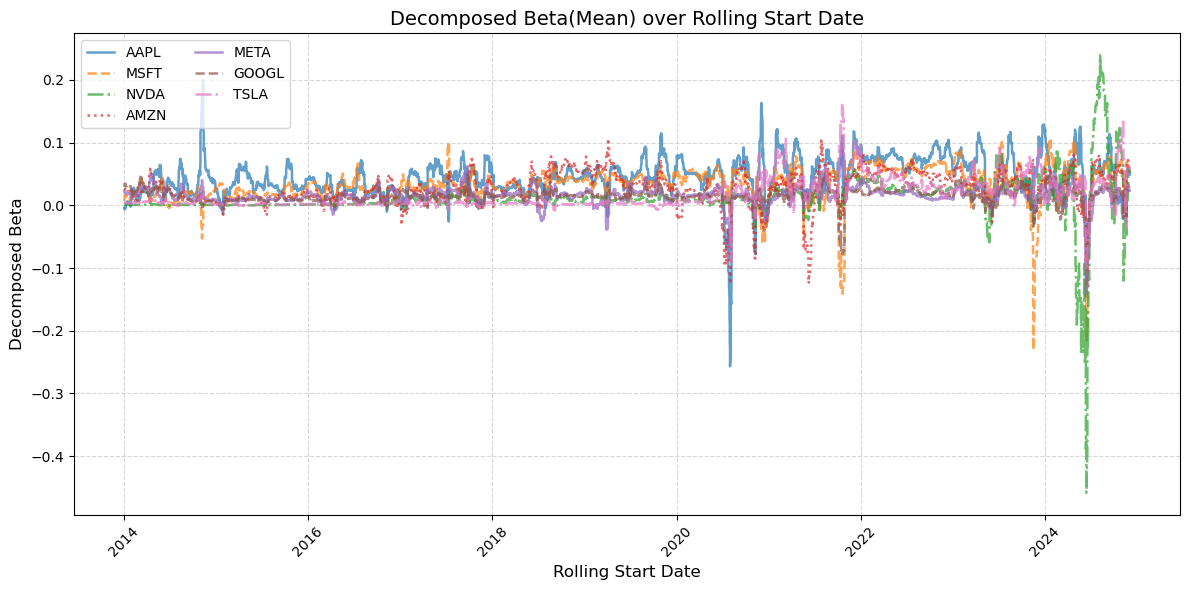

In [174]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

colors = sns.color_palette("tab10", n_colors=len(beta_results))
linestyles = ['-', '--', '-.', ':', '-', '--', '-.']

for idx, (key, df) in enumerate(beta_results.items()):
    df['mean_result'] = df.groupby(['rolling_start_date', 'rolling_end_date'])['result'].transform('mean')
    df = df.sort_values('rolling_start_date')
    
    plt.plot(df['rolling_start_date'], 
             df['mean_result'].rolling(window=5).mean(),  
             label=key, 
             color=colors[idx], 
             linestyle=linestyles[idx % len(linestyles)],
             linewidth=1.8, 
             alpha=0.7)  

plt.title('Decomposed Beta(Mean) over Rolling Start Date', fontsize=14)
plt.xlabel('Rolling Start Date', fontsize=12)
plt.ylabel('Decomposed Beta', fontsize=12)

plt.legend(fontsize=10, frameon=True, ncol=2, loc='upper left')  
plt.grid(True, linestyle='--', alpha=0.5)  
plt.xticks(rotation=45) 
plt.tight_layout()
plt.show()


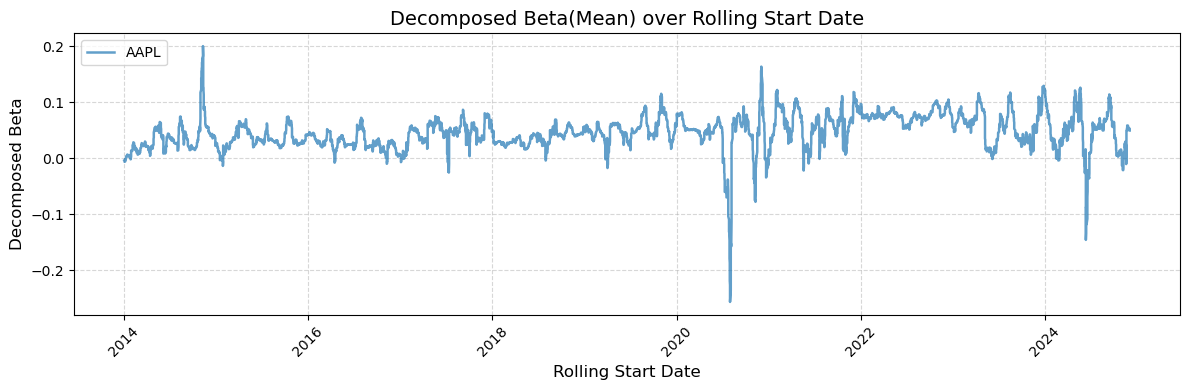

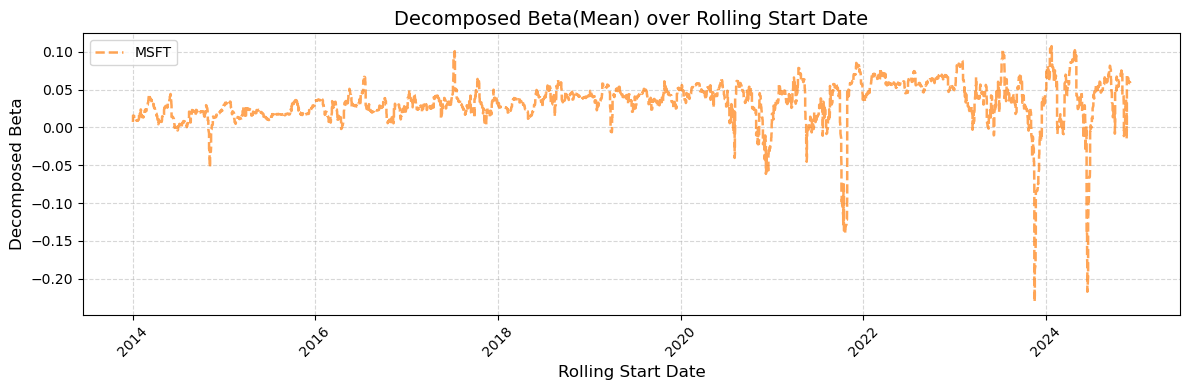

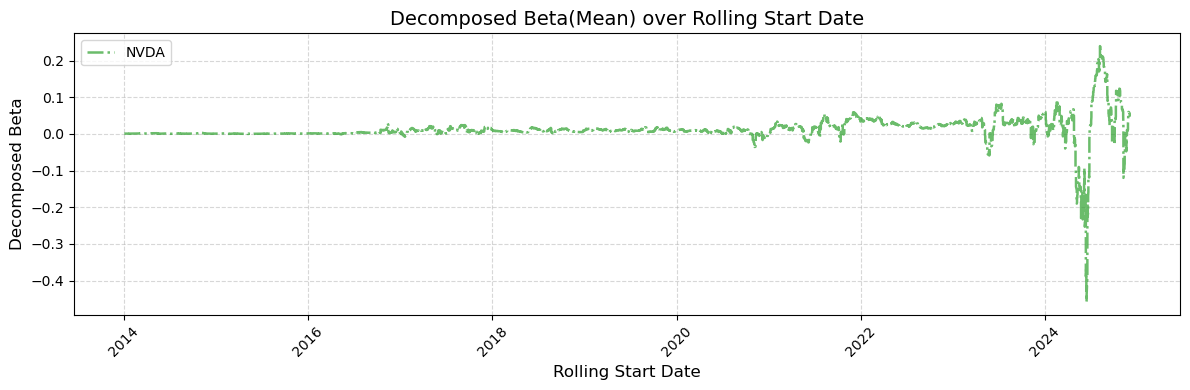

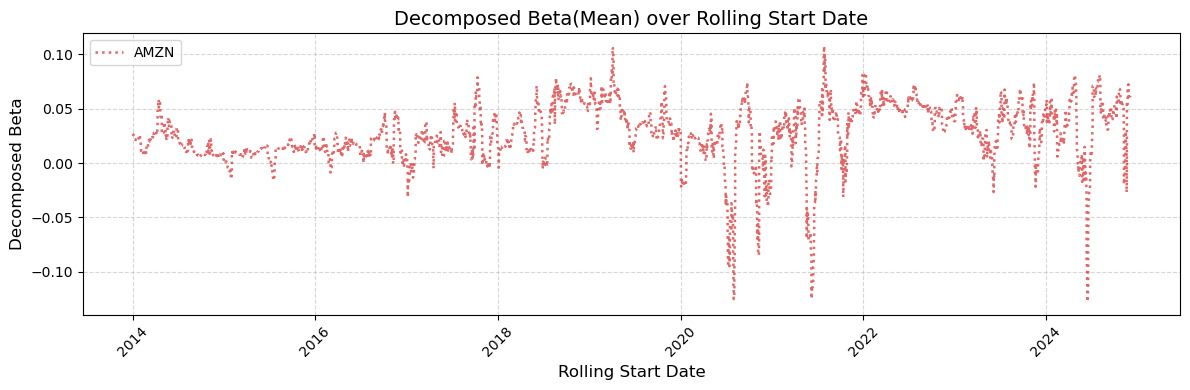

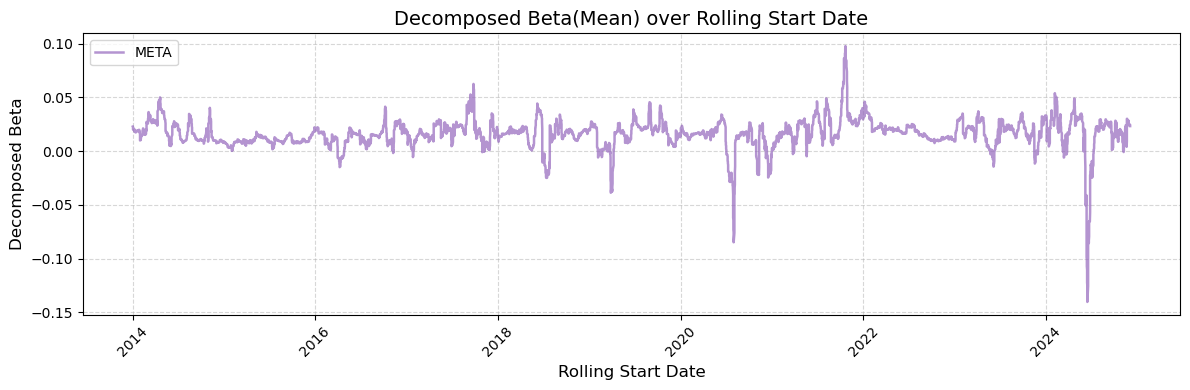

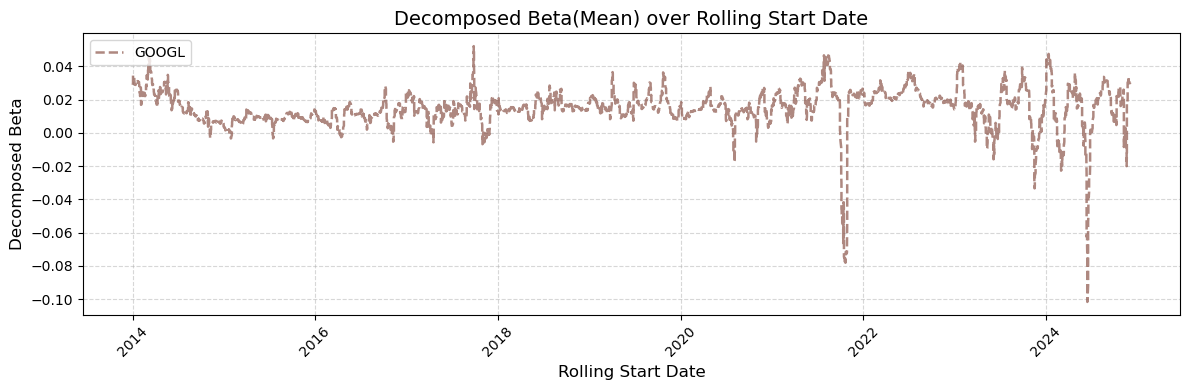

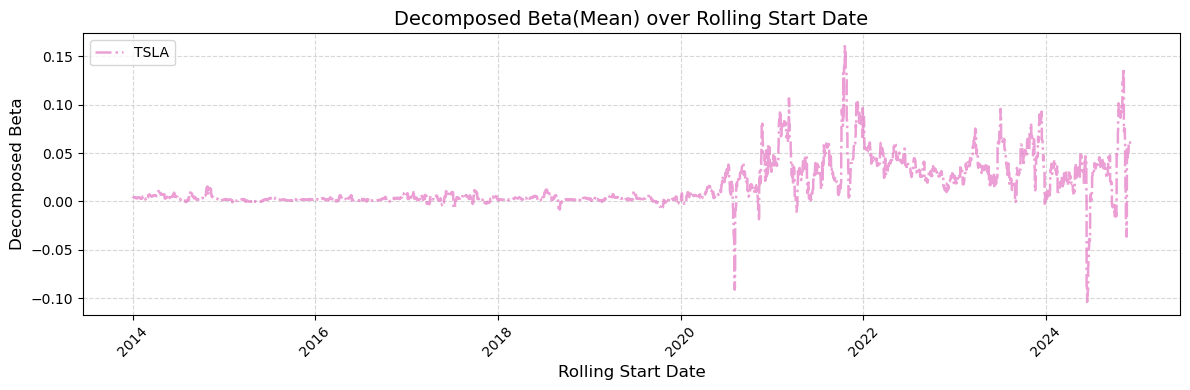

In [175]:
import matplotlib.pyplot as plt
import seaborn as sns

colors = sns.color_palette("tab10", n_colors=len(beta_results))
linestyles = ['-', '--', '-.', ':', '-', '--', '-.']

for idx, (key, df) in enumerate(beta_results.items()):
    
    df['mean_result'] = df.groupby(['rolling_start_date', 'rolling_end_date'])['result'].transform('mean')
    df = df.sort_values('rolling_start_date')
    plt.figure(figsize=(12, 4))
    plt.plot(df['rolling_start_date'], 
             df['mean_result'].rolling(window=5).mean(),  
             label=key, 
             color=colors[idx], 
             linestyle=linestyles[idx % len(linestyles)],
             linewidth=1.8, 
             alpha=0.7)  

    plt.title('Decomposed Beta(Mean) over Rolling Start Date', fontsize=14)
    plt.xlabel('Rolling Start Date', fontsize=12)
    plt.ylabel('Decomposed Beta', fontsize=12)

    plt.legend(fontsize=10, frameon=True, ncol=2, loc='upper left')  
    plt.grid(True, linestyle='--', alpha=0.5)  
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()  

In [185]:
# Industry
import pandas as pd

df_sector = pd.read_csv('new_sector.csv')  

df_sector = df_sector[['industry', 'permno']].dropna()

industry_dict = df_sector.groupby('industry')['permno'].apply(list).to_dict()

industry_dict.keys()
industry_dict_str = {key: [str(int(value)) for value in values] for key, values in industry_dict.items()}
industry_dict = industry_dict_str


In [224]:
beta_sector_result = {}
for key in industry_dict.keys():
    permno_columns = industry_dict[key]
    return_series = merged_df["R7"]
    weight_series = merged_df["weight7"]
    beta_sector_result[key] = cal_beta(permno_columns,return_series,weight_series,merged_df,252)
    

stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe


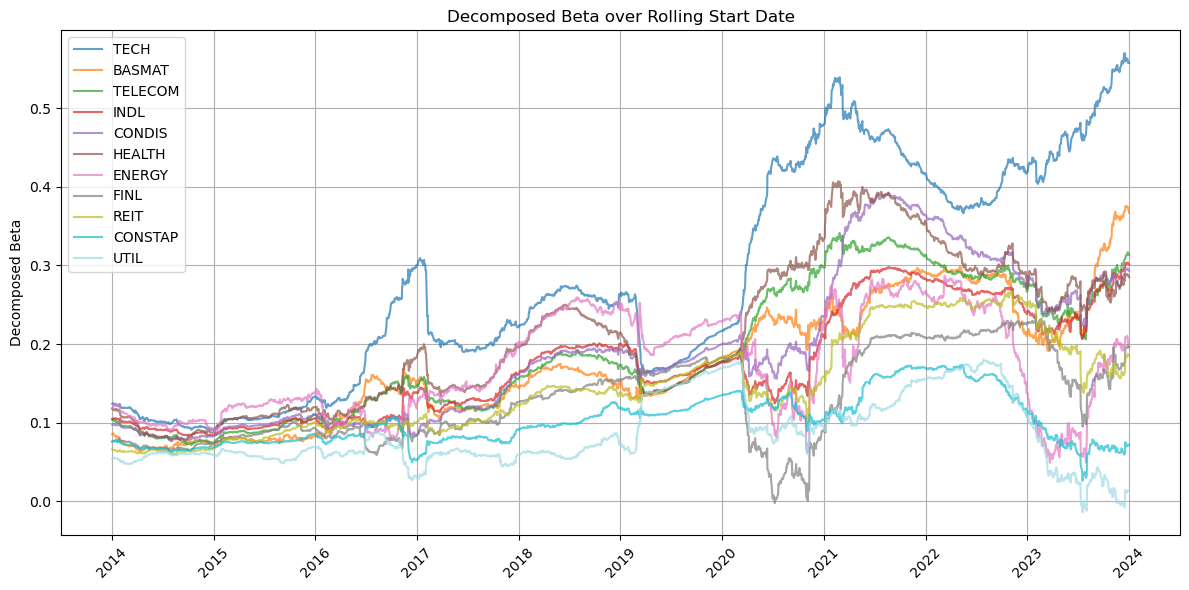

In [229]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

final_values = {}


for key in beta_sector_result.keys():
    beta_sector_result[key]['mean_result'] = beta_sector_result[key].groupby(
        ['rolling_start_date', 'rolling_end_date']
    )['result'].transform('mean')

    beta_sector_result[key] = beta_sector_result[key].sort_values('rolling_start_date')

    final_values[key] = beta_sector_result[key]['mean_result'].iloc[-1]

sorted_keys = sorted(final_values, key=final_values.get, reverse=True)

cmap = plt.get_cmap("tab20") 
colors = cmap(np.linspace(0, 1, len(sorted_keys)))

for i,key in enumerate(sorted_keys):
    plt.plot(beta_sector_result[key]['rolling_start_date'], 
             beta_sector_result[key]['mean_result'], 
             label=key, alpha=0.7,color=colors[i])

plt.title('Decomposed Beta over Rolling Start Date')
#plt.xlabel('Rolling Start Date')
plt.ylabel('Decomposed Beta')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [190]:
beta_sector_2result = {}
for key in industry_dict.keys():
    permno_columns = industry_dict[key]
    return_series = merged_df["R493"]
    weight_series = merged_df["weight493"]
    beta_sector_2result[key] = cal_beta(permno_columns,return_series,weight_series,merged_df,252)

stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe
stored one dataframe


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_1125/3158805429.py:15: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


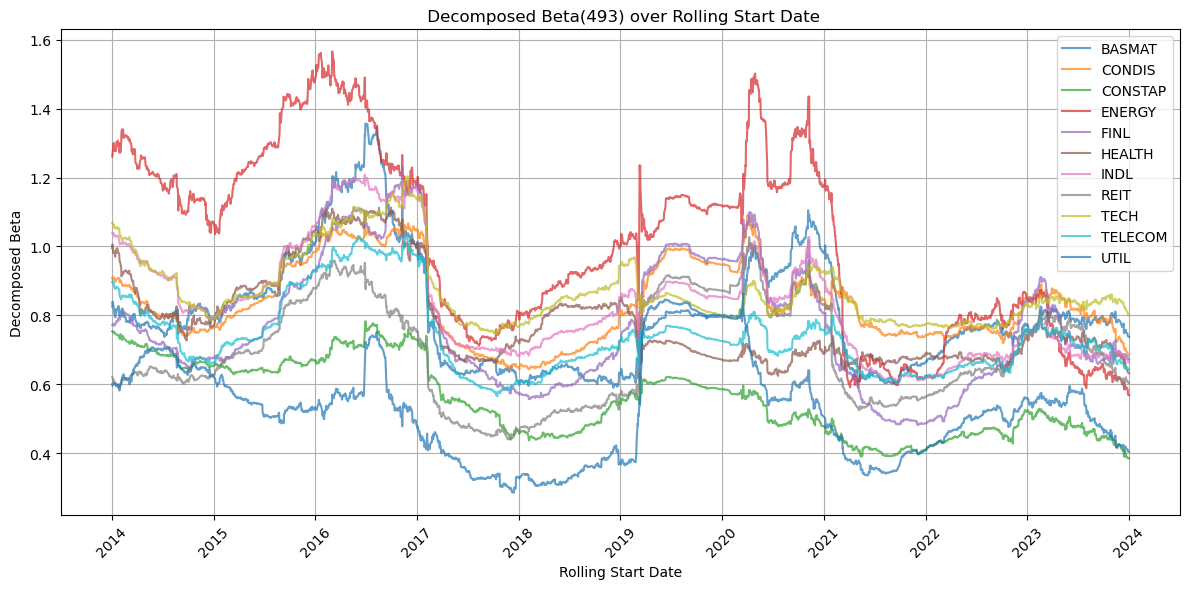

In [191]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
for key in beta_sector_2result.keys():
    beta_sector_2result[key]['mean_result'] = beta_sector_2result[key].groupby(['rolling_start_date', 'rolling_end_date'])['result'].transform('mean')
    beta_sector_2result[key] = beta_sector_2result[key].sort_values('rolling_start_date')
   
    plt.plot(beta_sector_2result[key]['rolling_start_date'], beta_sector_2result[key]['mean_result'], label=key, alpha=0.7)

plt.title(' Decomposed Beta(493) over Rolling Start Date')
plt.xlabel('Rolling Start Date')
plt.ylabel('Decomposed Beta')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

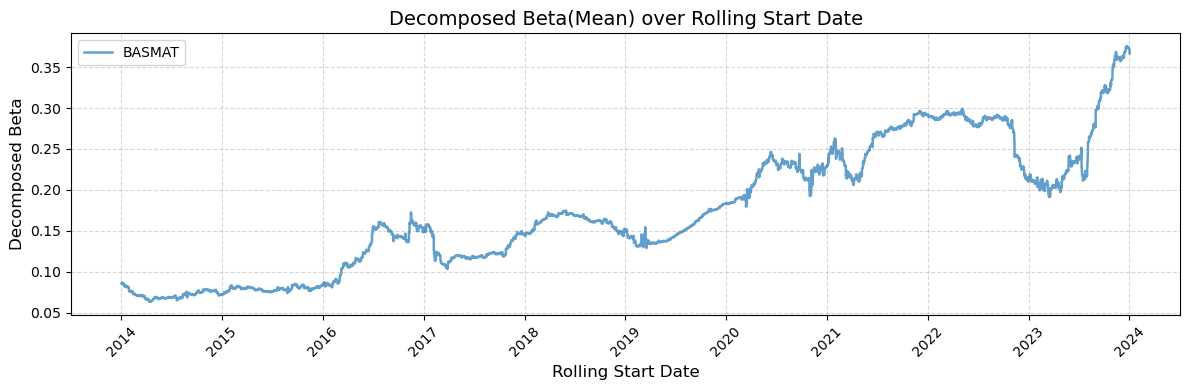

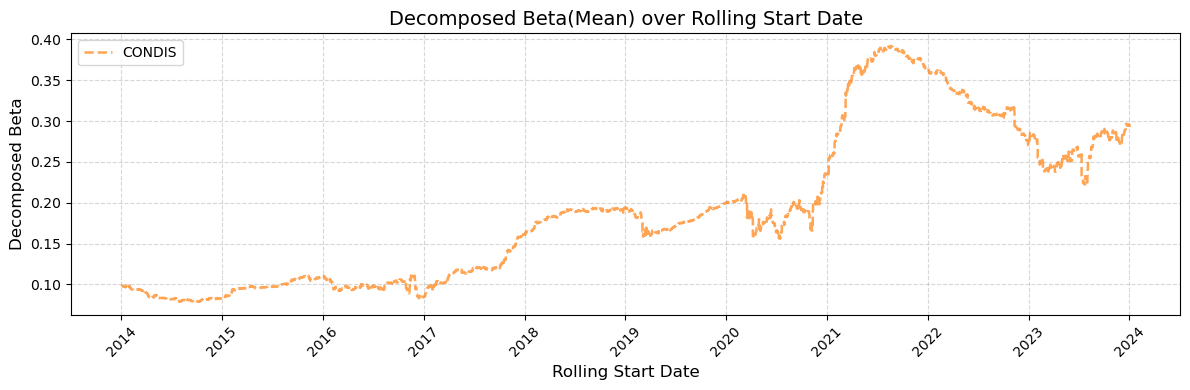

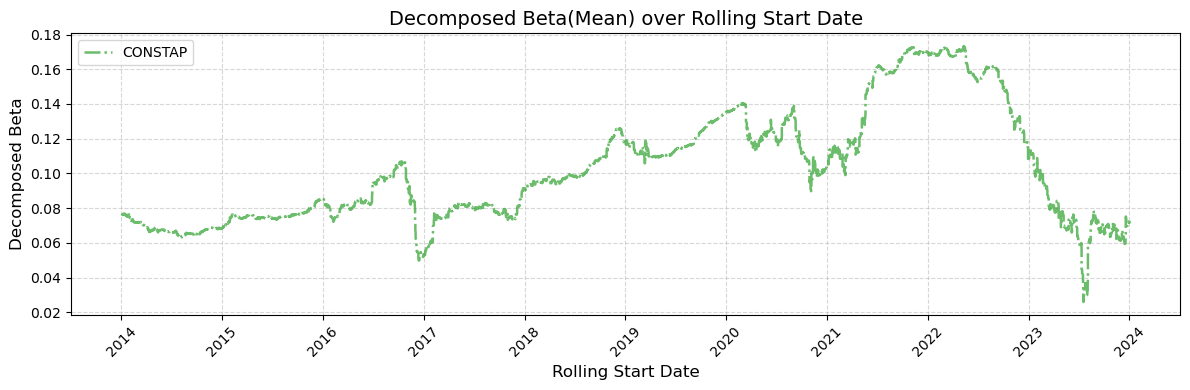

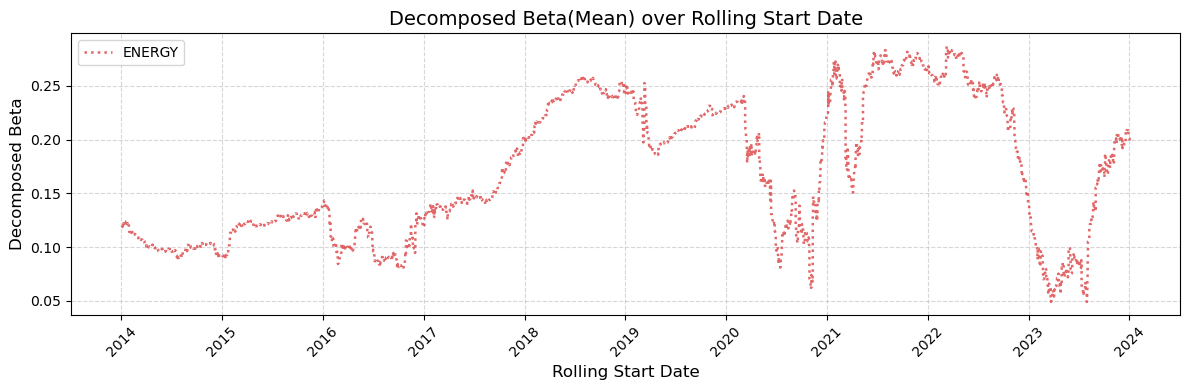

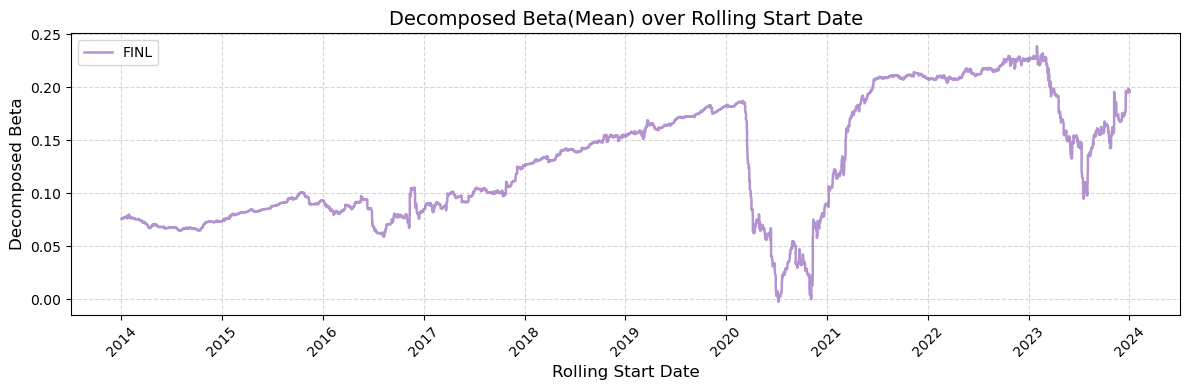

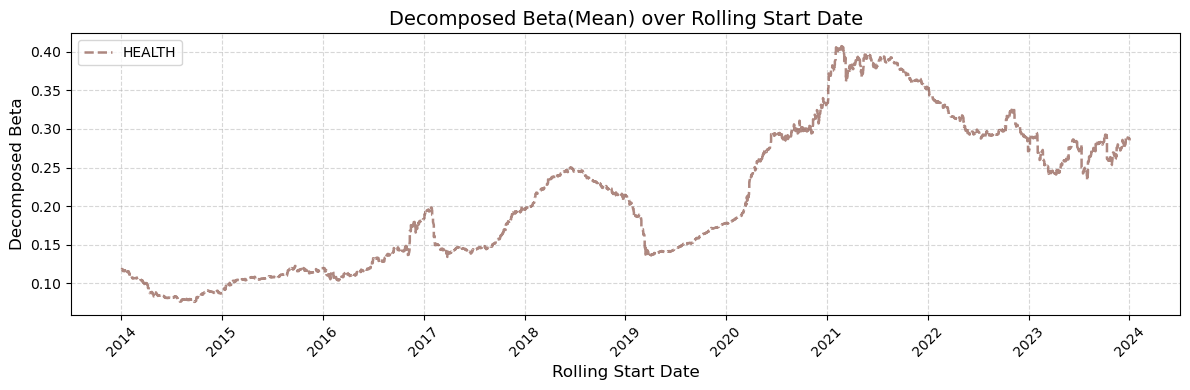

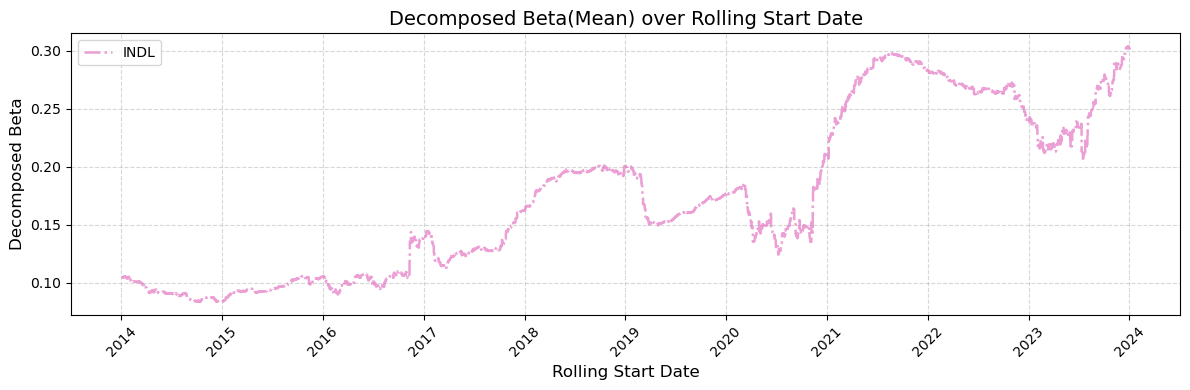

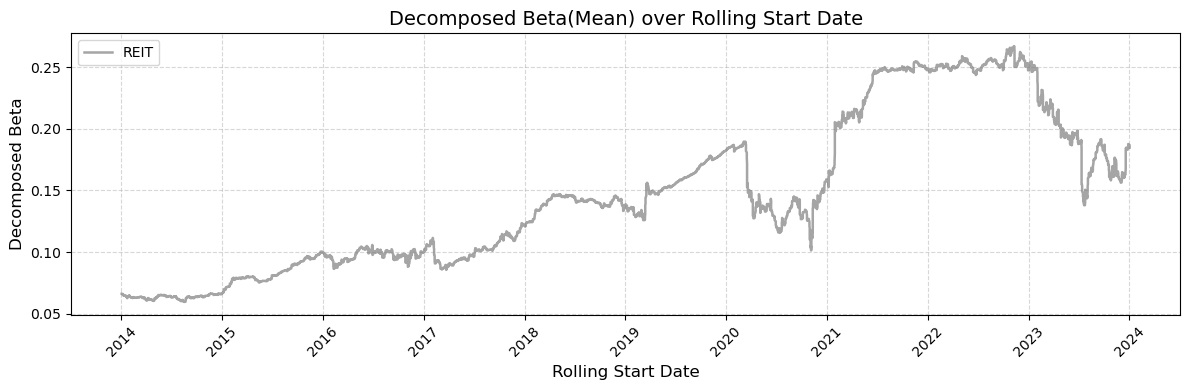

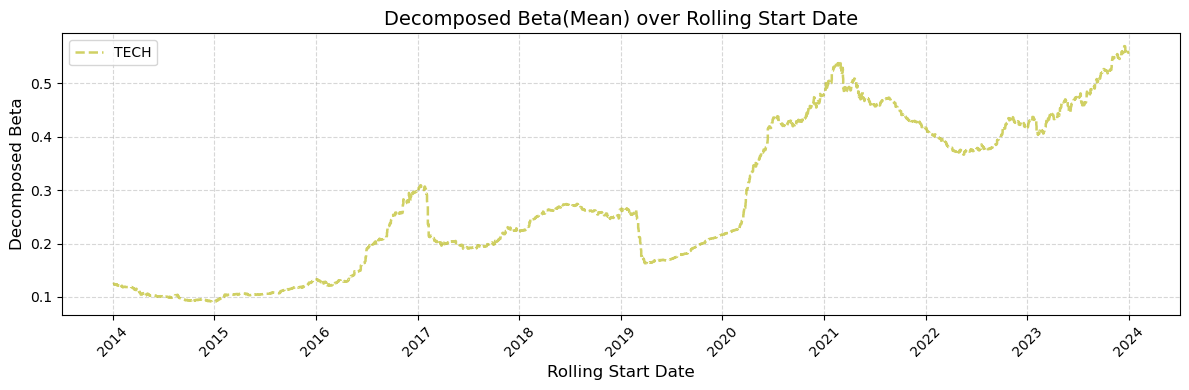

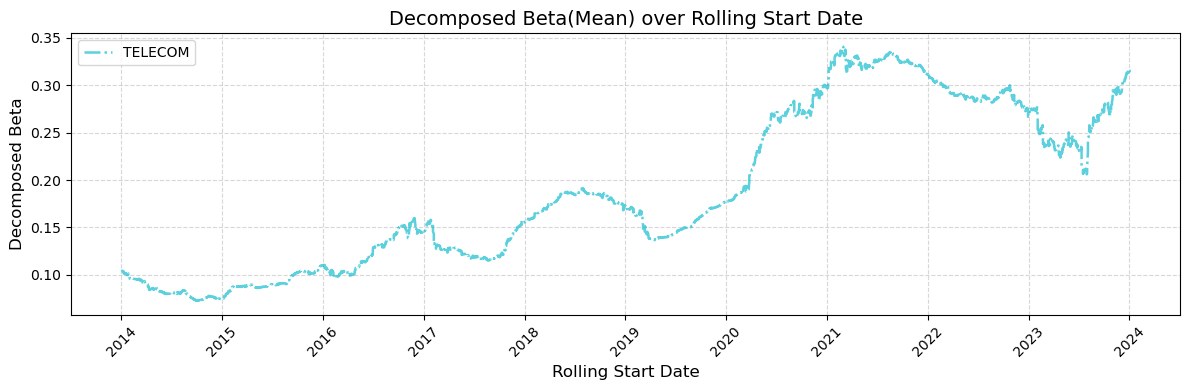

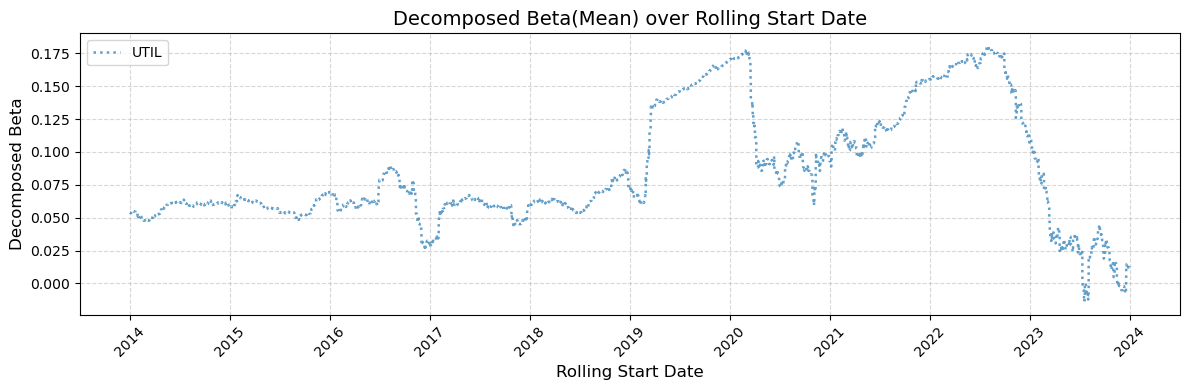

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns

colors = sns.color_palette("tab10", n_colors=len(beta_sector_result))
linestyles = ['-', '--', '-.', ':', '-', '--', '-.']

for idx, (key, df) in enumerate(beta_sector_result.items()):
    
    df['mean_result'] = df.groupby(['rolling_start_date', 'rolling_end_date'])['result'].transform('mean')
    df = df.sort_values('rolling_start_date')
    plt.figure(figsize=(12, 4))
    plt.plot(df['rolling_start_date'], 
             df['mean_result'].rolling(window=5).mean(),  
             label=key, 
             color=colors[idx], 
             linestyle=linestyles[idx % len(linestyles)],
             linewidth=1.8, 
             alpha=0.7)  

    plt.title('Decomposed Beta(Mean) over Rolling Start Date', fontsize=14)
    plt.xlabel('Rolling Start Date', fontsize=12)
    plt.ylabel('Decomposed Beta', fontsize=12)

    plt.legend(fontsize=10, frameon=True, ncol=2, loc='upper left')  
    plt.grid(True, linestyle='--', alpha=0.5)  
    plt.xticks(rotation=45) 
    plt.tight_layout()
    plt.show()  

In [81]:
date_index = merged_df['date'].values
start_dates = []
end_dates = []
for i in range(n):
    start_idx = max(0, i - window_size + 1)
    end_idx = i + 1
    start_dates.append(date_index[start_idx])
    end_dates.append(date_index[end_idx-1] if end_idx <= n else np.nan)

In [193]:
# Large Cap v.s. Small Cap
beta_cap_result1 = {'small':None,'large':None}
for key in beta_cap_result1.keys():
    return_series = merged_df["R7"]
    weight_series = merged_df["weight7"]
    beta_cap_result1[key] = cal_beta(permno_cols,return_series,weight_series,merged_df,126)

stored one dataframe
stored one dataframe


In [199]:
permno_cols_int = [int(i) for i in permno_cols]

In [200]:
import wrds
import pandas as pd

conn = wrds.Connection()
tickers_df = pd.read_csv('new_sector.csv')
all_permno = tickers_df['permno'].unique().tolist()
permno_list = [14593, 10107, 86580, 84788, 13407, 90319, 93436]
#WHERE permno IN ({', '.join(map(str, permno_list))})

query = f"""
    SELECT dlycaldt,dlycap,dlyprc,dlyret,dlyretx,dlyvol,permno,shrout,siccd,ticker
    FROM crsp.dsf_v2
      WHERE dlycaldt BETWEEN '2014-01-01' AND '2024-12-31'
      and permno IN ({', '.join(map(str, permno_cols_int))})
    ORDER BY dlycaldt, permno
"""

df_stock = conn.raw_sql(query)

df_stock['date'] = pd.to_datetime(df_stock['dlycaldt'])

print(df_stock.head())

WRDS recommends setting up a .pgpass file.
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
     dlycaldt        dlycap  dlyprc    dlyret   dlyretx      dlyvol  permno  \
0  2014-01-02  1.628049e+06   87.15 -0.016255 -0.016255     50930.0   10026   
1  2014-01-02  2.617840e+04    2.15 -0.035874 -0.035874     11300.0   10028   
2  2014-01-02  1.445408e+06   42.78 -0.011781 -0.011781    145207.0   10032   
3  2014-01-02  7.063980e+04   11.55 -0.005168 -0.005168      9933.0   10044   
4  2014-01-02  1.701820e+08   37.84 -0.010978 -0.010978  18163700.0   10104   

    shrout  siccd ticker       date  
0    18681   2052   JJSF 2014-01-02  
1    12176   5094   DGSE 2014-01-02  
2    33787   3670   PLXS 2014-01-02  
3     6116   2060   RMCF 2014-01-02  
4  4497409   7379   ORCL 2014-01-02  


In [201]:
df_stock.to_csv('stock_dsf.csv')

In [202]:
df_cap = pd.read_csv("stock_dsf.csv", parse_dates=["dlycaldt"])
df_cap['dlycaldt'] = pd.to_datetime(df_cap['dlycaldt']).dt.date
top_30_dict = {}
bottom_30_dict = {}

for start, end in zip(start_dates, end_dates):
    window_df = df_cap[(df_cap["dlycaldt"] >= start) & (df_cap["dlycaldt"] <= end)]

    avg_dlycap = window_df.groupby("permno")["dlycap"].mean()

    sorted_permno = avg_dlycap.sort_values(ascending=False)

    num_top = int(len(sorted_permno) * 0.3)
    num_bottom = int(len(sorted_permno) * 0.3)

    top_30_dict[str(start)] = sorted_permno.index[:num_top].tolist()
    bottom_30_dict[str(start)] = sorted_permno.index[-num_bottom:].tolist()


In [203]:
beta_cap_result1['large']

,rolling_start_date,rolling_end_date,permno,result
0,2014-01-02,2014-07-02,10026,0.080530
1,2014-01-03,2014-07-03,10026,0.079308
2,2014-01-06,2014-07-07,10026,0.078603
3,2014-01-07,2014-07-08,10026,0.079122
4,2014-01-08,2014-07-09,10026,0.078383
...,...,...,...,...
5584654,2024-06-27,2024-12-24,93436,1.599300
5584655,2024-06-28,2024-12-26,93436,1.603654
5584656,2024-07-01,2024-12-27,93436,1.616510
5584657,2024-07-02,2024-12-30,93436,1.584084


In [230]:
def filter_group(group):
    start_date = group.name[0]
    #print(start_date.strftime('%Y-%m-%d'))
    valid_permnos = top_30_dict.get(str(start_date.strftime('%Y-%m-%d')), [])
    valid_permnos = [str(x) for x in valid_permnos]
    return group[group['permno'].isin(valid_permnos)]

filtered_df = beta_cap_result1['large'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)

mean_result_df1 = filtered_df.groupby('rolling_start_date')['result'].mean().reset_index()
mean_result_df1.columns = ['rolling_start_date', 'mean_result']

print(mean_result_df1.head())

  rolling_start_date  mean_result
0         2014-01-02     0.099351
1         2014-01-03     0.099336
2         2014-01-06     0.098272
3         2014-01-07     0.099108
4         2014-01-08     0.099118


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_1125/2598931130.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df = beta_cap_result1['large'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)


In [231]:
def filter_group(group):
    start_date = group.name[0]
    #print(start_date.strftime('%Y-%m-%d'))
    valid_permnos = bottom_30_dict.get(str(start_date.strftime('%Y-%m-%d')), [])
    valid_permnos = [str(x) for x in valid_permnos]
    return group[group['permno'].isin(valid_permnos)]
filtered_df2 = beta_cap_result1['small'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)

mean_result_df2 = filtered_df2.groupby('rolling_start_date')['result'].mean().reset_index()
mean_result_df2.columns = ['rolling_start_date', 'mean_result']

print(mean_result_df2.head())

  rolling_start_date  mean_result
0         2014-01-02     0.105135
1         2014-01-03     0.107048
2         2014-01-06     0.107328
3         2014-01-07     0.109007
4         2014-01-08     0.108744


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_1125/149148308.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df2 = beta_cap_result1['small'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)


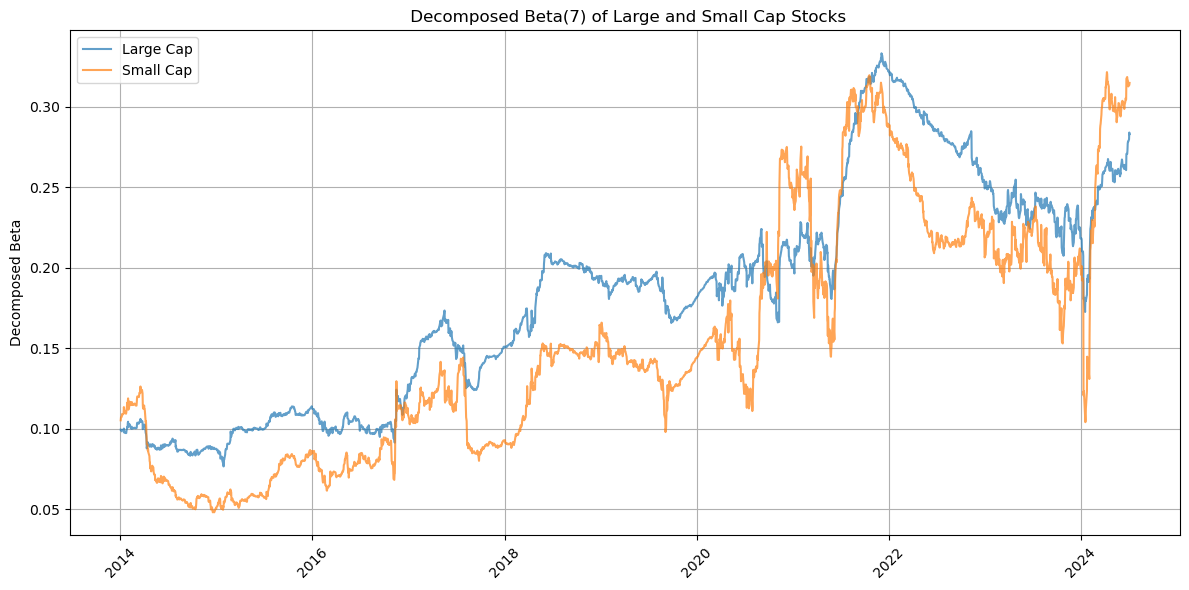

In [236]:
plt.figure(figsize=(12, 6))
plt.plot(mean_result_df1['rolling_start_date'], mean_result_df1['mean_result'], label='Large Cap', alpha=0.7)
plt.plot(mean_result_df2['rolling_start_date'],mean_result_df2['mean_result'], label='Small Cap', alpha=0.7)
plt.title(' Decomposed Beta(7) of Large and Small Cap Stocks')
#plt.xlabel('Rolling Start Date')
plt.ylabel('Decomposed Beta')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [208]:
beta_cap_result2 = {'small':None,'large':None}
for key in beta_cap_result2.keys():
    return_series = merged_df["R493"]
    weight_series = merged_df["weight493"]
    beta_cap_result2[key] = cal_beta(permno_cols,return_series,weight_series,merged_df,126)

stored one dataframe
stored one dataframe


In [232]:
def filter_group(group):
    start_date = group.name[0]
    #print(start_date.strftime('%Y-%m-%d'))
    valid_permnos = top_30_dict.get(str(start_date.strftime('%Y-%m-%d')), [])
    valid_permnos = [str(x) for x in valid_permnos]
    return group[group['permno'].isin(valid_permnos)]

filtered_df = beta_cap_result2['large'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)

mean_result_df3 = filtered_df.groupby('rolling_start_date')['result'].mean().reset_index()
mean_result_df3.columns = ['rolling_start_date', 'mean_result']

print(mean_result_df3.head())

  rolling_start_date  mean_result
0         2014-01-02     0.966255
1         2014-01-03     0.966450
2         2014-01-06     0.968967
3         2014-01-07     0.966962
4         2014-01-08     0.966306


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_1125/2128236743.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df = beta_cap_result2['large'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)


In [233]:
def filter_group(group):
    start_date = group.name[0]
    #print(start_date.strftime('%Y-%m-%d'))
    valid_permnos = bottom_30_dict.get(str(start_date.strftime('%Y-%m-%d')), [])
    valid_permnos = [str(x) for x in valid_permnos]
    return group[group['permno'].isin(valid_permnos)]
filtered_df2 = beta_cap_result2['small'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)

mean_result_df4 = filtered_df2.groupby('rolling_start_date')['result'].mean().reset_index()
mean_result_df4.columns = ['rolling_start_date', 'mean_result']

print(mean_result_df4.head())

  rolling_start_date  mean_result
0         2014-01-02     0.830945
1         2014-01-03     0.853005
2         2014-01-06     0.860317
3         2014-01-07     0.869117
4         2014-01-08     0.864841


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_1125/4059897298.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df2 = beta_cap_result2['small'].groupby(['rolling_start_date', 'rolling_end_date'], group_keys=False).apply(filter_group)


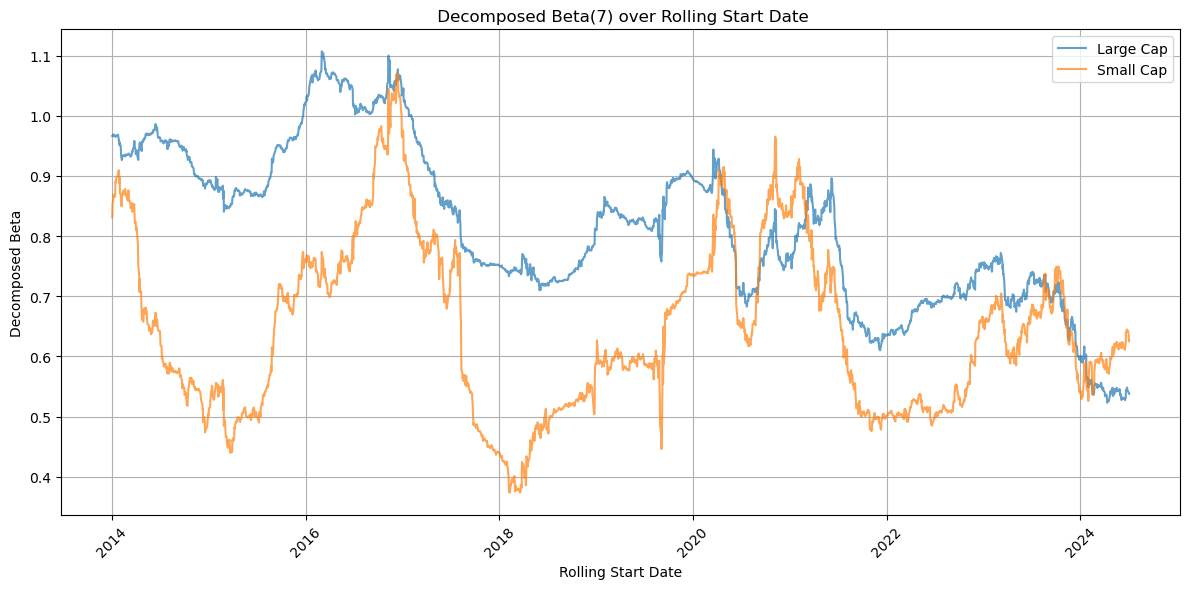

In [211]:
plt.figure(figsize=(12, 6))
plt.plot(mean_result_df3['rolling_start_date'], mean_result_df3['mean_result'], label='Large Cap', alpha=0.7)
plt.plot(mean_result_df4['rolling_start_date'], mean_result_df4['mean_result'], label='Small Cap', alpha=0.7)
plt.title(' Decomposed Beta(7) over Rolling Start Date')
plt.xlabel('Rolling Start Date')
plt.ylabel('Decomposed Beta')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

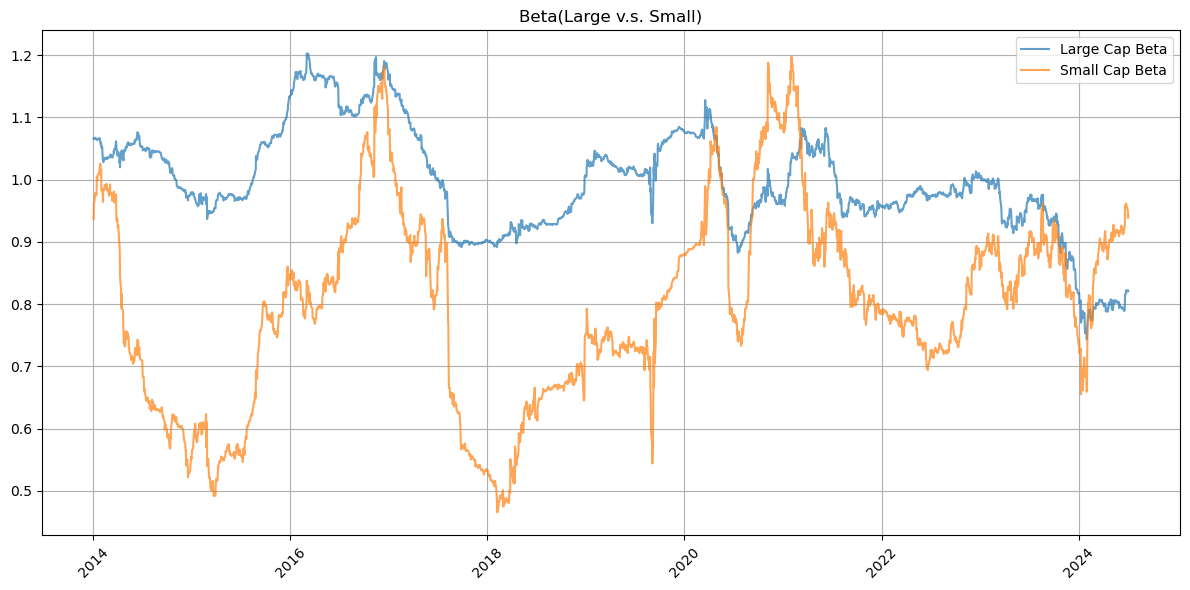

In [234]:
plt.figure(figsize=(12, 6))
plt.plot(mean_result_df3['rolling_start_date'], mean_result_df1['mean_result']+mean_result_df3['mean_result'], label='Large Cap Beta', alpha=0.7)
plt.plot(mean_result_df4['rolling_start_date'], mean_result_df2['mean_result']+mean_result_df4['mean_result'], label='Small Cap Beta', alpha=0.7)
plt.title('Beta(Large v.s. Small)')
#plt.xlabel('Rolling Start Date')
#plt.ylabel('Decomposed Beta')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [121]:
data_2 = pd.read_csv('F-F_Research_Data_Factors_daily.csv',index_col = 0)
FF_data = data_2.loc[20140102:]
FF_data.index = pd.to_datetime(FF_data.index,format='%Y%m%d')
FF_data

,Mkt-RF,SMB,HML,RF
2014-01-02,-0.88,-0.28,0.18,0.000
2014-01-03,0.03,0.36,0.04,0.000
2014-01-06,-0.34,-0.57,0.29,0.000
2014-01-07,0.68,0.38,-0.37,0.000
2014-01-08,0.04,-0.01,-0.11,0.000
...,...,...,...,...
2024-12-24,1.11,-0.09,-0.05,0.017
2024-12-26,0.02,1.04,-0.19,0.017
2024-12-27,-1.17,-0.66,0.56,0.017
2024-12-30,-1.09,0.12,0.74,0.017


In [123]:
merged_df['date'] = pd.to_datetime(merged_df['date'])
FF_data.index = pd.to_datetime(FF_data.index, format='%Y%m%d')

merged_df = merged_df.set_index('date')
FF_data = FF_data.copy()

merged_df = pd.concat([merged_df, FF_data], axis=1)


In [176]:
beta_cap_result = {'R7':None,'R493':None}

return_series = merged_df["R7"]
weight_series = merged_df["weight7"]
beta_cap_result['R7'] = cal_beta(permno_cols,return_series,weight_series,merged_df,126)
return_series = merged_df["R493"]
weight_series = merged_df["weight493"]
beta_cap_result['R493'] = cal_beta(permno_cols,return_series,weight_series,merged_df,126)

stored one dataframe
stored one dataframe


In [ ]:
import pandas as pd

r7_weight = pd.read_csv("r7_weight.csv")

r7_weight['date'] = pd.to_datetime(r7_weight['date'])

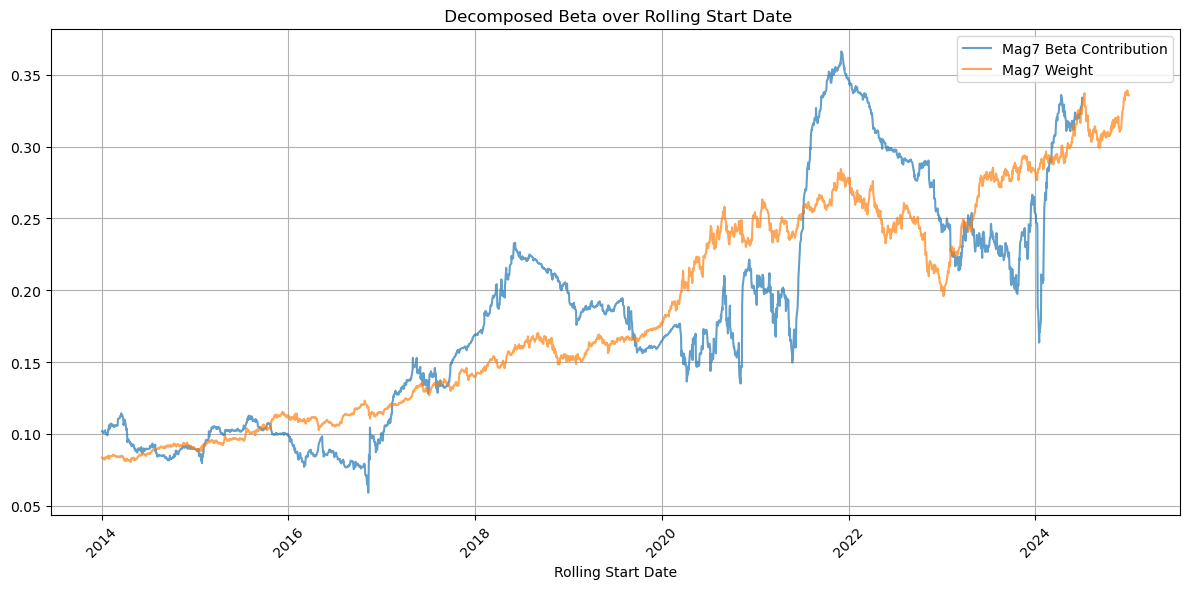

In [220]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
for key in beta_cap_result.keys():
    beta_cap_result[key]['mean_result'] = beta_cap_result[key].groupby(['rolling_start_date', 'rolling_end_date'])['result'].transform('mean')
    beta_cap_result[key] = beta_cap_result[key].sort_values('rolling_start_date')
   
#plt.plot(beta_cap_result['R7']['rolling_start_date'], beta_cap_result['R7']['mean_result'], label='Mag7 Beta', alpha=0.7)
#plt.plot(beta_cap_result['R7']['rolling_start_date'], beta_cap_result['R7']['mean_result']+beta_cap_result['R493']['mean_result'], label='Overall Beta', alpha=0.7)
plt.plot(beta_cap_result['R7']['rolling_start_date'], beta_cap_result['R7']['mean_result']/(beta_cap_result['R7']['mean_result']+beta_cap_result['R493']['mean_result']), label='Mag7 Beta Contribution', alpha=0.7)
#plt.plot(beta_cap_result['R493']['rolling_start_date'], beta_cap_result['R493']['mean_result'], label='Left 493 Beta', alpha=0.7)
plt.plot(r7_weight['date'], r7_weight['weight'], label='Mag7 Weight', alpha=0.7)

plt.title(' Decomposed Beta over Rolling Start Date')
plt.xlabel('Rolling Start Date')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()